# CLEVR questions as sLTN formulas: perfect sight (E0)

**The dataset.** CLEVR (Johnson et al., CVPR 2017) is a visual question-answering benchmark. Each image is a rendered scene with 3 to 10 simple objects on a grey floor. Every object has four **attributes**: a colour (8 values), a shape (cube, sphere, cylinder), a size (small, large) and a material (rubber, metal). About a million questions are asked about these scenes, such as *"What color is the matte thing in front of the large cube?"* or *"Are there any other things that are the same shape as the big metallic object?"*. Every question comes with its answer and with a **functional program**: a small tree of operations (find the cubes, take the large one, look in front of it, ...) whose execution on the scene gives the answer. The programs come from 90 templates, called **question families**.

**Where we are going.** The goal of the CLEVR experiments is to train small networks that recognise the four attributes of an object **without any attribute label**: the only supervision is the answers to the questions. Each question's program is turned into a logical formula that ties the answer to the networks' outputs, and sLTN trains the networks to make the formulas true. This is the pattern of the digits-from-order example (MNIST digits learned only from "which digit came before which" answers), on a well-known benchmark, with four concepts and relations between objects.

**This notebook: the step before learning.** Before training anything, we must be sure that the formulas mean exactly what the programs mean. So here nothing is learned: the attributes of every object are read from CLEVR's scene annotations, which the paper calls **perfect sight**. With perfect attributes, a correct formula must reproduce the dataset's answer on *every* question. If it disagrees even once, the translation is wrong, and no amount of training would fix it.

**Why it is done this way:**
- **Programs, not English.** We use each question's program and skip the English text. The program is the exact meaning of the question; parsing the text is a separate problem (most neuro-symbolic CLEVR work also starts from programs).
- **Formulas generated, not hand-written.** There are 60 families in scope, and the programs of one family still vary (which values they name, "left" or "behind"). A small compiler turns any program into a formula, and all the questions of a family share one formula (see the model below).
- **Counting is left out.** About a third of the questions ask "how many" or compare two counts. Counting isn't a first-order quantifier, so these questions stay out for now.

**The model in words.** Each question family has one fixed formula: its program written in logic, with symbols for the parts that change from question to question (the values the question names, such as "large" and "cube", and the directions, such as "front"). For a given question, we ground these symbols with the question's values and with its scene (here, the true attributes and positions of the objects). sLTN then computes the formula's truth value, and that value is read as the reply: above 0.5 means "yes"; for "what color" questions there is one truth value per colour, and the highest is the reply.

For example, family 75 is the template *"what color is the ⟨filter 2⟩ object that is ⟨direction⟩ of the ⟨filter 1⟩ object?"*. Two of its questions:

| Question | Filter 1 | Direction | Filter 2 | Answer |
|---|---|---|---|---|
| *What color is the matte thing in front of the large cube?* | large, cube | front | matte (rubber) | cyan |
| *There is a small ball left of the gray metallic sphere; what color is it?* | gray, metallic (metal), sphere | left | small, ball (sphere) | brown |

The questions use synonyms of the attribute values (matte = rubber, shiny or metallic = metal, ball = sphere, tiny = small, ...); the program always uses the value itself, given in parentheses. The English differs, but the program has the same shape. So both questions use the same formula, and only the values in the table change. A filter can name any of the four attributes; an attribute it doesn't name (the colour of "the large cube") is grounded so that it accepts every value. For each question, the formula gives one truth value per colour, and the highest one should be cyan for the first question and brown for the second. The two scenes are shown right after the setup cell.

**What this example shows:**
- **The objects of a scene as a structural dimension.** Scenes have 3 to 10 objects; each scene gets 10 positions, the empty ones marked as not present, so a batch of scenes is one tensor. ∃ ranges over the objects of each scene. It is a structural dimension that isn't time.
- **Many questions in one pass.** The questions of a batch are a second structural dimension: question `q` has its own scene, values and answer, all indexed by `q`, so they stay together.
- **Given relations as structural relations.** Left, right, front and behind come from the dataset and enter the formulas as structural relations over pairs of objects.
- **One formula per family, with parameters.** A question's values are constants of the formula; an attribute the question doesn't name is grounded with the all-ones vector, which makes its atom exactly true.
- **Nested quantifiers.** "The thing in front of the large cube" introduces one ∃ per object the question mentions, nested in the order of the program.
- **Questions whose answer is a value, not yes/no.** "What color is ...?" becomes a formula with a free variable over the 8 colours: one truth value per colour, saying whether that colour is the answer.
- **Choosing the ∃ aggregator.** ∃ over objects uses `max`, which is exact on true/false values.

**Compute.** CPU, about 30 s in all: a few seconds to load the validation files, about 15 s to check the 101,028 in-scope questions.

**Data.** [CLEVR](https://cs.stanford.edu/people/jcjohns/clevr/) (Johnson et al., CVPR 2017), licensed CC BY 4.0. The first run downloads the scene and question files (`CLEVR_v1.0_no_images.zip`, 85 MB) into `notebooks/datasets/`. The images are only in the full 18 GB archive, so the 12 validation images this notebook shows are included in `images/`.

In [1]:
import collections
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch

import sltn
from sltn import Interpretation, Logic, Signature
from sltn.interpretation.operators.aggregator import AggregMax, AggregPMeanError

sys.path.insert(0, str(Path.cwd().resolve()))         # notebooks/examples/CLEVR
from clevr_sltn import DATA, IMAGES, download, sltn_version

download()                                            # CLEVR's scene and question files (85 MB), the first time
print("sltn:", sltn_version())

sltn: {'commit': 'ae8335e9ae6e4eac7303f12a969f2ffc60fe7b8f', 'branch': 'bug-fixes-temp', 'dirty': True}


**The two questions of family 75 from the introduction**, with their scenes. The object picked by filter 1 is framed in blue; the object the question asks about, picked by the direction and filter 2, in orange. (The validation files are loaded here; Section 1 describes them.)

loaded in 3s


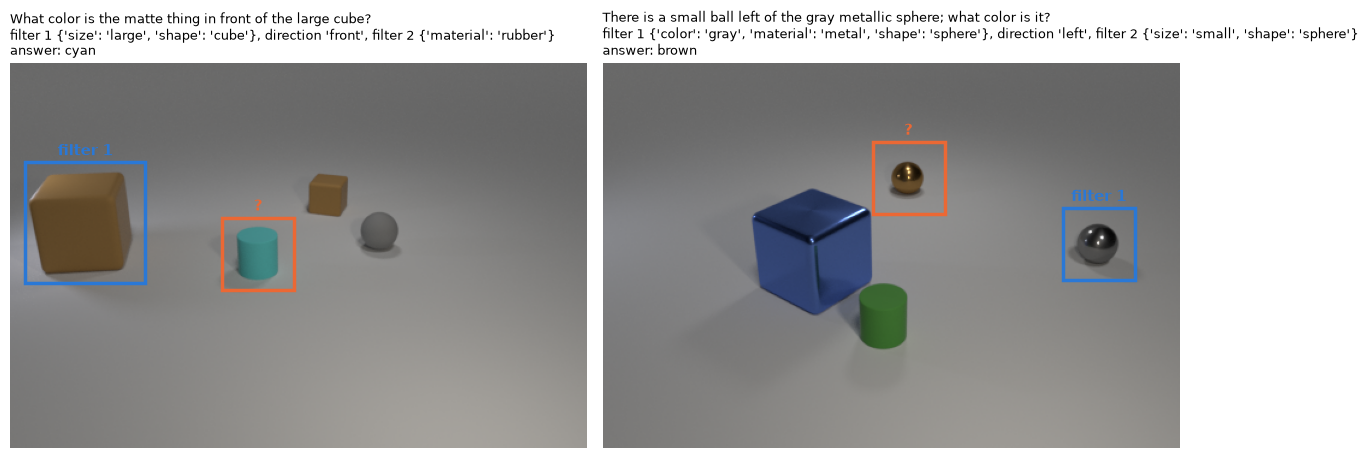

In [2]:
t0 = time.perf_counter()
scenes = json.load(open(DATA / "scenes" / "CLEVR_val_scenes.json"))["scenes"]
questions = json.load(open(DATA / "questions" / "CLEVR_val_questions.json"))["questions"]
print(f"loaded in {time.perf_counter() - t0:.0f}s")


def family75_parts(q):
    # filter 1, direction, filter 2 of a family-75 program: the filters before `relate` are filter 1
    f1, f2, d = {}, {}, None
    for n in q["program"]:
        if n["function"].startswith("filter_"):
            (f2 if d else f1)[n["function"][len("filter_"):]] = n["value_inputs"][0]
        elif n["function"] == "relate":
            d = n["value_inputs"][0]
    return f1, d, f2


def matching(objs, vals):
    return [i for i, ob in enumerate(objs) if all(ob[a] == v for a, v in vals.items())]


examples = ["What color is the matte thing in front of the large cube?",
            "There is a small ball left of the gray metallic sphere; what color is it?"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, text in zip(axes, examples):
    q = next(q for q in questions if q["question"] == text)
    s = scenes[q["image_index"]]
    f1, d, f2 = family75_parts(q)
    (ref,) = matching(s["objects"], f1)                                   # unique, by construction
    (target,) = [i for i in s["relationships"][d][ref] if i in matching(s["objects"], f2)]
    ax.imshow(plt.imread(IMAGES / s["image_filename"]))
    for i, colour, label in ((ref, "#2a78d6", "filter 1"), (target, "#eb6834", "?")):
        x, y, _ = s["objects"][i]["pixel_coords"]
        h = 50 if s["objects"][i]["size"] == "large" else 30                   # half side of the frame, in pixels
        ax.add_patch(plt.Rectangle((x - h, y - h), 2 * h, 2 * h, fill=False, ec=colour, lw=2.5))
        ax.text(x, y - h - 6, label, color=colour, fontsize=11, weight="bold", ha="center")
    ax.set_title(f"{text}\nfilter 1 {f1}, direction {d!r}, filter 2 {f2}\nanswer: {q['answer']}",
                 fontsize=9, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 1. The dataset

CLEVR v1.0 has three splits of scenes: 70,000 train, 15,000 val and 15,000 test images. The test answers aren't public, so val is used as the test set. For train and val there are two kinds of files besides the images:

- `scenes/CLEVR_<split>_scenes.json`: one entry per image, with every object's attributes and position, and the spatial relations between the objects;
- `questions/CLEVR_<split>_questions.json`: one entry per question (about 10 per image), with its text, program, family and answer.

We use the validation split here. The train split was checked with the script `e0_perfect_sight.py` (Section 6).

In [3]:
print(f"{len(scenes)} scenes, {len(questions)} questions")
print("objects per scene:", dict(sorted(collections.Counter(len(s["objects"]) for s in scenes).items())))

15000 scenes, 149991 questions
objects per scene: {3: 1898, 4: 1925, 5: 1843, 6: 1852, 7: 1808, 8: 1941, 9: 1877, 10: 1856}


### 1.1 A scene

Scene 0 of the validation split and its annotation. For every object, the scene file gives:
- the four attributes: `color`, `shape`, `size`, `material`;
- its position: `3d_coords` in the rendered world, `pixel_coords` in the image (x, y and depth), and a `rotation`.

The image below is numbered with the index of each object in the file, placed at its `pixel_coords`.

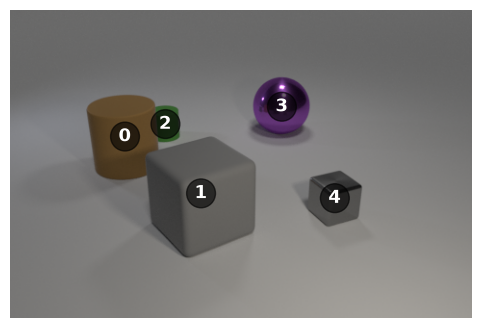

object 0: large brown  rubber cylinder pixel (x, y) = [119, 131]
object 1: large gray   rubber cube     pixel (x, y) = [198, 190]
object 2: small green  rubber cylinder pixel (x, y) = [161, 118]
object 3: large purple metal  sphere   pixel (x, y) = [282, 100]
object 4: small gray   metal  cube     pixel (x, y) = [337, 195]


In [4]:
scene = scenes[0]
img = plt.imread(IMAGES / scene["image_filename"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(img)
for i, ob in enumerate(scene["objects"]):
    x, y, _ = ob["pixel_coords"]
    ax.text(x, y, str(i), color="white", fontsize=13, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="circle", fc="black", alpha=0.6))
ax.axis("off")
plt.show()
for i, ob in enumerate(scene["objects"]):
    print(f"object {i}: {ob['size']:5s} {ob['color']:6s} {ob['material']:6s} {ob['shape']:8s} pixel (x, y) = {ob['pixel_coords'][:2]}")

**Spatial relations.** The scene file also lists, for each direction, which objects are in that direction from each object: `relationships["right"][i]` is the list of objects to the right of object `i`. Directions are those of the camera: "right" means further right in the image, "front" means closer to the camera. CLEVR computes them from the 3D positions (an object is right of another if it is further along the camera's right vector, by more than a small margin), so they are fixed and exact.

In [5]:
for d in ("left", "right", "front", "behind"):
    print(f"{d:7s}", {i: objs for i, objs in enumerate(scene["relationships"][d])})

left    {0: [], 1: [0, 2], 2: [0], 3: [0, 1, 2], 4: [0, 1, 2, 3]}
right   {0: [1, 2, 3, 4], 1: [3, 4], 2: [1, 3, 4], 3: [4], 4: []}
front   {0: [1, 4], 1: [], 2: [0, 1, 4], 3: [0, 1, 2, 4], 4: [1]}
behind  {0: [2, 3], 1: [0, 2, 3, 4], 2: [3], 3: [], 4: [0, 2, 3]}


For example, `right[0] = [1, 2, 3, 4]`: every other object is right of the brown cylinder (object 0), the leftmost one in the image.

### 1.2 A question

Each question stores its text, its answer, its family (`question_family_index`, 0–89) and its program. The program is a list of nodes in execution order; each node has a `function`, its `inputs` (indices of earlier nodes) and its `value_inputs` (the values it names, such as `"large"`).

In [6]:
def show_program(q):
    for i, n in enumerate(q["program"]):
        args = ", ".join([f"#{j}" for j in n["inputs"]] + [repr(v) for v in n["value_inputs"]])
        print(f"  #{i}: {n['function']}({args})")

for q in [q for q in questions if q["image_index"] == 0][:3]:
    print(f"{q['question']}  ->  {q['answer']}   (family {q['question_family_index']})")
    show_program(q)

Are there any other things that are the same shape as the big metallic object?  ->  no   (family 39)
  #0: scene()
  #1: filter_size(#0, 'large')
  #2: filter_material(#1, 'metal')
  #3: unique(#2)
  #4: same_shape(#3)
  #5: exist(#4)
Is there a big brown object of the same shape as the green thing?  ->  yes   (family 47)
  #0: scene()
  #1: filter_color(#0, 'green')
  #2: unique(#1)
  #3: same_shape(#2)
  #4: filter_size(#3, 'large')
  #5: filter_color(#4, 'brown')
  #6: exist(#5)
What is the material of the big purple object?  ->  metal   (family 87)
  #0: scene()
  #1: filter_size(#0, 'large')
  #2: filter_color(#1, 'purple')
  #3: unique(#2)
  #4: query_material(#3)


The functions, and what they compute on a scene:

| Function | Input → output | Meaning |
|---|---|---|
| `scene` | → set of objects | all the objects of the scene |
| `filter_<attr>(v)` | set → set | the objects of the set whose `<attr>` is `v` |
| `unique` | set → object | the only object of the set (the questions are generated so that it has exactly one) |
| `relate(d)` | object → set | the objects in direction `d` of the object |
| `same_<attr>` | object → set | the *other* objects with the same `<attr>` as the object |
| `intersect`, `union` | set, set → set | intersection, union |
| `exist` | set → yes/no | is the set non-empty? |
| `query_<attr>` | object → value | the object's `<attr>` |
| `equal_<attr>` | value, value → yes/no | are the two values equal? |
| `count` | set → number | the size of the set |
| `equal_integer`, `less_than`, `greater_than` | number, number → yes/no | comparisons of counts |

The question types, named after the program's last function:

In [7]:
COUNTING = {"count", "equal_integer", "less_than", "greater_than"}
def qtype(q):
    f = q["program"][-1]["function"]
    return "query" if f.startswith("query_") else "compare" if f.startswith("equal_") and f != "equal_integer" \
        else "count / compare counts" if f in COUNTING else f
types = collections.Counter(qtype(q) for q in questions)
for t, n in types.most_common():
    print(f"{t:24s} {n:6d}  {n / len(questions):.0%}")

query                     53734  36%
count / compare counts    48963  33%
compare                   27098  18%
exist                     20196  13%


## 2. What we take, and why

| From CLEVR | Used? | Why |
|---|---|---|
| Object attributes (scene file) | **Here: as perfect sight.** Later: only to score the networks | In this notebook they replace the networks. When learning, the networks will see the images, and the attributes will never be used in training |
| Object list (scene file) | Yes | Which objects exist and how many (3–10); the image would need an object detector for this, which isn't what we study |
| Spatial relations (scene file) | Yes, as given | They are part of the dataset's definition (computed from 3D positions). Learning them from the answers is a possible extension |
| Pixel and 3D coordinates, rotation | Not here | Later, the pixel coordinates locate each object in the image (one crop per object) |
| Programs | Yes | The exact meaning of each question, turned into a formula |
| Question text | No | It says the same as the program; parsing English is a different problem |
| Answers | Yes | Here, to check the formulas; later, the only supervision |
| Counting questions (about 32%) | No | "How many" isn't expressible with ∀ and ∃ |
| Test split | No | Its answers aren't public |

In [8]:
qs = [q for q in questions if not any(n["function"] in COUNTING for n in q["program"])]
print(f"in scope: {len(qs)} of {len(questions)} questions ({len(qs) / len(questions):.0%}), "
      f"{len({q['question_family_index'] for q in qs})} of 90 families")

in scope: 101028 of 149991 questions (67%), 60 of 90 families


## 3. From a program to a formula

### 3.1 How a batch of questions is laid out

A batch holds questions of one family, possibly about different scenes. Two structural dimensions organise it:

- **`Question`, structural variable `q`:** one position per question of the batch. Everything that belongs to a question (its scene, its values, its answer) is a constant indexed by `q`, so all of them stay aligned: position `q` is one question with its own scene and its own values. A scene asked ten questions appears ten times.
- **`Obj`, structural variables `o1, o2, ...`:** the objects of the question's scene. A question that mentions three objects uses three of these variables, one per object, numbered in the order the program meets them.

**Padding.** Scenes have 3 to 10 objects, but a batch is one tensor, which needs the same size for every scene. So every scene gets 10 positions for objects: the real objects fill the first ones, and the rest are empty. `Present(q, o)` marks which positions hold a real object:

```
scene with 5 objects:  [obj0, obj1, obj2, obj3, obj4, empty, empty, empty, empty, empty]
Present:               [  1,    1,    1,    1,    1,    0,     0,     0,     0,     0  ]
```

Every formula includes `Present`, so an empty position can never be "the large cube", and ∃ over the objects only finds real ones.

Why a structural axis for the questions, rather than an ordinary variable? sLTN combines the values of different variables as a Cartesian product: two variables over B scenes and B parameters would give B × B entries, pairing every scene with every question's parameters. Putting the question index on one axis that all the constants share keeps each scene with its own question. (This is the layout of the graph-colouring example, with graphs there and questions here.)

### 3.2 The symbols

| Symbol | Kind | Grounding |
|---|---|---|
| `x[q, o]` | constant, sort `Feat`, dims `Question × Obj` | the object's appearance. Here: its four attributes as one-hot vectors, concatenated: 8 (colours) + 2 (sizes) + 2 (materials) + 3 (shapes) = 15 numbers |
| `color`, `size`, `material`, `shape` | functions `Feat → Col`, `Siz`, ... | a distribution over the attribute's values. Here: the slice of `x` that holds that attribute. Later: a network |
| `IsC`, `IsZ`, `IsM`, `IsS` | predicates on two values of one attribute | the dot product of two distributions: 1 if two one-hot vectors are equal, 0 otherwise |
| `Present(q, o)` | structural relation | 1 for a real object, 0 for an empty position |
| `Neq(o1, o2)` | structural relation | 1 − identity: "o2 is another object than o1" |
| `R0, R1, ...(q, o1, o2)` | structural relations | one per `relate` step of the program, numbered from 0 in program order. `Rk(q, o1, o2)` is 1 iff, in question `q`'s scene, object `o2` is in the direction named by the `k`-th `relate`, seen from object `o1`. Example: if relate 0 says "front", `R0(q, o1, o2)` = 1 iff `o2` is in front of `o1` |
| `ck, zk, mk, sk` `[q]` (k = 0, 1, ...) | constants indexed by `q` | one group of four per filter step of the program, numbered from 0 in program order: the colour, size, material and shape that question `q`'s `k`-th filter asks for, one-hot, or all-ones for an attribute the filter doesn't name. Example: if filter 0 says "large cube", `z0[q]` = one-hot(large), `s0[q]` = one-hot(cube), `c0[q]` and `m0[q]` = all-ones |
| `Yes(q)` | structural relation | ground truth: 1 if the dataset's answer to yes/no question `q` is "yes", 0 if "no" |
| `ac, az, am, as_` `[q]` | constants indexed by `q` | ground truth: the dataset's answer to "what ...?" question `q`, one-hot (`ac` for colour, `az` size, `am` material, `as_` shape) |
| `kc, kz, km, ks` | variables | range over the 8 colours, 2 sizes, 2 materials, 3 shapes |


**In short:** `Present` keeps the empty positions out; `color`, `size`, `material` and `shape` return a distribution over the attribute's values (here one-hot, from the scene file; later a network's softmax); `IsC` & co. check whether two values of an attribute match (a dot product: exactly 1 or 0 for one-hot vectors, a probability for a network's output); `&` is ∧, computed as a product; `c0[q]` is the colour that filter 0 of question `q` asks for: one-hot if the question names a colour, all-ones ("any colour") if it doesn't.

### 3.3 A worked example: one question, step by step

Before the general rules, one question from start to end: *"What color is the matte thing in front of the large cube?"* (answer: cyan). Its program, as stored in the dataset, grouped into phases:

```
#0: scene()                          ┐
#1: filter_size(#0, 'large')         │ filter 0: "the large cube"
#2: filter_shape(#1, 'cube')         │
#3: unique(#2)                       ┘   → one object: o1
#4: relate(#3, 'front')                relate 0: "in front of o1"
#5: filter_material(#4, 'rubber')    ┐ filter 1: "matte" (= rubber)
#6: unique(#5)                       ┘   → one object: o2
#7: query_color(#6)                    the question: the colour of o2
```

As a chain of phases, each turning a set of objects into a smaller one:

```
all objects ──filter 0──► the large cube (o1) ──relate 0──► objects in front of o1 ──filter 1──► the matte one (o2) ──query──► its colour
              large, cube                          front                               rubber                                  cyan
```

Every `unique` gives one object, and the object variables are numbered in program order: `o1` is the large cube, `o2` the matte thing. Each phase becomes a piece of the formula, and its parameters (the values the question names) become symbols grounded for this question:

| Steps | Phase | Symbols, grounded for this question | Formula piece | Reads |
|---|---|---|---|---|
| #0 | scene | — | `Present(q, o1)` | o1 is a real object (not an empty position) |
| #1–#2 | filter 0 | `c0[q]` = all-ones (no colour named)<br>`z0[q]` = one-hot(large)<br>`m0[q]` = all-ones (no material named)<br>`s0[q]` = one-hot(cube) | `IsC(color(x[q, o1]), c0[q])`<br>`& IsZ(size(x[q, o1]), z0[q])`<br>`& IsM(material(x[q, o1]), m0[q])`<br>`& IsS(shape(x[q, o1]), s0[q])` | o1 has any colour, is large, has any material, is a cube |
| #3 | unique | — | `exists o1: (...)` | there is such an object: "the large cube" |
| #4 | relate 0 | `R0(q, o1, o2)` = the "front" relation of this scene | `R0(q, o1, o2)` | o2 is in front of o1 |
| #5 | filter 1 | `c1[q]` = all-ones, `z1[q]` = all-ones<br>`m1[q]` = one-hot(rubber), `s1[q]` = all-ones | `IsC(color(x[q, o2]), c1[q])`<br>`& IsZ(size(x[q, o2]), z1[q])`<br>`& IsM(material(x[q, o2]), m1[q])`<br>`& IsS(shape(x[q, o2]), s1[q])` | o2 is rubber (any colour, size, shape) |
| #6 | unique | — | `exists o2: (...)` | there is such an object: "the matte thing in front of the large cube" |
| #7 | query_color | `kc`: a variable over the 8 colours | `IsC(color(x[q, o2]), kc)` | o2 has colour kc |

**Why all-ones.** `IsC(color(x[q, o1]), c0[q])` is the dot product of o1's colour distribution with `c0[q]`. With a one-hot `c0[q]` (say "red"), it is the probability that o1 is red. With `c0[q]` all-ones, it is the sum of o1's colour probabilities, which is exactly 1: the atom is true whatever o1's colour. So "filter 0 doesn't name a colour" is written as "filter 0 accepts every colour", and the formula keeps the same four atoms for every question of the family.

**The numbers in the names count different things.** In `c1`, `R1` and `o1`, the 1 means filter 1, relate 1 and object variable 1. They aren't linked: `c1[q]` is not the colour of `o1`, it's the colour that filter 1 of question `q` asks for (here none, so all-ones; filter 1 is "matte" and applies to `o2`). Filters and relates are counted from 0, objects from 1. The colour of an object is `color(x[q, o])`, computed from the object.

**The whole formula**, as the compiler writes it (Section 3.6), with each line marked by the step it comes from:

```
exists o2: (                                                       # #6 unique: the matte thing
    Present(q, o2)
  & exists o1: (                                                   # #3 unique: the large cube
        Present(q, o1)                                             # #0 scene
      & IsC(color(x[q, o1]), c0[q]) & IsZ(size(x[q, o1]), z0[q])   # #1-#2 filter 0: large cube
      & IsM(material(x[q, o1]), m0[q]) & IsS(shape(x[q, o1]), s0[q])
      & R0(q, o1, o2))                                             # #4 relate 0: o2 in front of o1
  & IsC(color(x[q, o2]), c1[q]) & IsZ(size(x[q, o2]), z1[q])       # #5 filter 1: matte
  & IsM(material(x[q, o2]), m1[q]) & IsS(shape(x[q, o2]), s1[q])
  & IsC(color(x[q, o2]), kc))                                      # #7 query_color
```

The large cube's part sits inside the matte thing's, because the matte thing is defined from it. Its value for each colour `kc` says whether "the matte thing in front of the large cube has colour `kc`". Section 4.3 evaluates it, phase by phase, on this question's scene.

### 3.4 The general translation

The worked example generalises step by step. Every program step does one of three things:

- it **picks objects** (`scene`, the filters, `relate`, `same_<attr>`, `intersect`): it adds a condition on an object, such as "o2 is rubber";
- it **names an object** (`unique`): "the large cube" becomes a new variable, `o1`, `o2`, ... in program order, bound by ∃;
- it **answers** (the last step: `exist`, `query_<attr>` or `equal_<attr>`).

**Steps that pick objects.** In the formulas below, "o1 is a small gray cube" is short for the four filter atoms on `o1`.

| Step | Adds to the formula | Example from the dataset |
|---|---|---|
| `scene` | `Present(q, o)`: o is a real object | every program starts with it |
| `filter_<attr>` (several in a row form one filter) | the four atoms on o, with the filter's values (all-ones for an attribute it doesn't name) | "the large cube": `z0[q]` = large, `s0[q]` = cube |
| `relate` | `R0(q, o1, o2)`: o2 is in the direction of o1 | "in front of the large cube" (Section 3.3) |
| `same_color` (also size, material, shape) | `Neq(o1, o2) & IsC(color(x[q, o1]), color(x[q, o2]))`: o2 is another object with the same colour as o1 | *"Is there another block that has the same color as the tiny cube?"* |
| `intersect` | the conditions of its two branches, joined with `&`, on the same object | *"... a thing that is both to the left of the gray sphere and to the right of the small cylinder ..."* |

**The last step.** After it, every object variable is bound by an ∃. What stays free is `q` (one value per question) and, for "what ...?" questions, the variable over the values:

| Last step | Formula | Free variables: the reply | Example from the dataset |
|---|---|---|---|
| `exist` | `exists o2: (conditions on o2)` | `q`: one truth value per question; above 0.5 is "yes" | *"There is a small gray block; are there any spheres to the left of it?"* → `exists o2: (exists o1: (o1 is a small gray cube & R0(q, o1, o2)) & o2 is a sphere)` |
| `query_color` | `exists o2: (conditions on o2 & IsC(color(x[q, o2]), kc))` | `q` and `kc`: 8 truth values per question; the highest is the reply | *"What color is the matte thing in front of the large cube?"* (Section 3.3) |
| `equal_color` | `exists o1: (conditions on o1 & exists o2: (conditions on o2 & IsC(color(x[q, o1]), color(x[q, o2]))))` | `q`: one truth value per question | *"Do the large metal sphere and the matte block have the same color?"* → `exists o1: (o1 is a large metal sphere & exists o2: (o2 is a rubber cube & IsC(color(x[q, o1]), color(x[q, o2]))))` |

Two choices behind this:

- **"The" is written with ∃.** CLEVR only asks about "the large cube" when the scene has exactly one, so "the large cube is red" means the same as "there is a large cube that is red". (When the networks learn, ∃ won't check that there is only one; with perfect sight it doesn't need to.)
- **Each direction is a symbol of the question.** One question of a family says "left of", another "behind". So each `relate` gets its own relation `R0`, `R1`, ..., grounded per question with the direction it names. Here the relations come from the dataset; later a network could compute them.

### 3.5 The rule of a family

The question's formula (Sections 3.3 and 3.4) describes what the question asks. Evaluated on a scene, it gives sLTN's reply. To train networks, we need a statement that is true when that reply agrees with the dataset's answer, the **ground truth**. Two kinds of symbols hold the ground truth of each question:

- `Yes(q)`: 1 if the dataset's answer to question `q` is "yes", 0 if it is "no";
- `ac[q]`: the dataset's answer to a "what color" question, one-hot; for the running question of Section 3.3, *"What color is the matte thing in front of the large cube?"* (answer: cyan), `ac[q]` = cyan = `[0, 0, 0, 0, 0, 0, 1, 0]`. `az`, `am`, `as_` are the same for size, material and shape.

The **rule** of a family says "the question's formula is true exactly when the ground truth says so", for every question of the batch. Writing φ for the question's formula:

- yes/no questions: `forall q: (Yes(q) <-> φ)`. It holds for question `q` if φ is true and the answer is "yes", or φ is false and the answer is "no".
- "what color" questions: `forall q: forall kc: (IsC(kc, ac[q]) <-> φ)`. `IsC(kc, ac[q])` is 1 when `kc` is the given colour, 0 otherwise. So the rule asks φ to be true for the given colour and false for the 7 others.

For the running question, with φ = "the matte thing in front of the large cube has colour `kc`" and ground truth cyan:

| `kc` | `IsC(kc, ac[q])` (ground truth) | φ with perfect sight | `<->` |
|---|---|---|---|
| cyan | 1 | 1 | true |
| red (and the other 6) | 0 | 0 | true |

If a network saw the cylinder as red, φ would be 0 for cyan and 1 for red, and both rows would be false: the rule would be violated, and training would push the network towards cyan.

In this notebook φ is used in two ways: alone, to read sLTN's reply and compare it with the ground truth (Section 5), and inside the rule, to check that the rule is satisfied. When learning, the rule is what the networks are trained on.

### 3.6 The compiler

The compiler does two separate jobs, because a family has one formula but each question has its own values:

- **`canonical(program)`, once per question:** separates the program's *shape* from its *values*. It returns the **skeleton** (the program with the values removed, the same string for every question of a family), the values of each filter, and the direction of each `relate`.
- **`Builder(program)`, once per family:** writes the question's formula, step by step, following the table of Section 3.4. It writes only symbol names (`c0[q]`, `R0`, ...), never values, so every question of the family gets the same text.

The values from `canonical` become the groundings of the symbols (Section 4.1). Both functions walk the program in the same order and number the filters and relates as they meet them, so filter `k` of the question grounds the symbols `ck, zk, mk, sk` of the formula, and relate `k` grounds `Rk`.

First, the names the code uses for attributes, values and symbols:

In [9]:
VALUES = {
    "color": ["gray", "red", "blue", "green", "brown", "purple", "cyan", "yellow"],
    "size": ["small", "large"],
    "material": ["rubber", "metal"],
    "shape": ["cube", "sphere", "cylinder"],
}
ATTRS = list(VALUES)
SORT = {"color": "Col", "size": "Siz", "material": "Mat", "shape": "Shp"}
IS = {"color": "IsC", "size": "IsZ", "material": "IsM", "shape": "IsS"}
PARAM = {"color": "c", "size": "z", "material": "m", "shape": "s"}      # filter slot k: c<k>, z<k>, m<k>, s<k>
ANS = {"color": "ac", "size": "az", "material": "am", "shape": "as_"}
KVAR = {"color": "kc", "size": "kz", "material": "km", "shape": "ks"}
OFFSET, start = {}, 0
for a in ATTRS:                                       # where each attribute sits in x: color 0:8, size 8:10, ...
    OFFSET[a] = (start, start + len(VALUES[a]))
    start += len(VALUES[a])
FEAT, O, DIRS = start, 10, ["left", "right", "front", "behind"]
SET_FUNCTIONS = ("scene", "relate", "intersect", "union")

**`canonical`** starts from the last step of the program and follows the inputs back to `scene`. On the way:

- a run of filter steps (`filter_size(large)`, then `filter_shape(cube)`) becomes **one filter slot**, written `F(...)` in the skeleton, and its values are collected in a dictionary: `{size: large, shape: cube}`;
- a step that picks objects but has no filter after it (a bare `scene`, a `relate` with nothing after) gets an **empty** slot, `F(...)` with `{}`: this is what makes the skeleton the same whether or not a question names a filter there;
- each `relate` records its direction, and the direction is left out of the skeleton.

The lists come out in the order the program meets the steps, starting from `scene`. For the running question, *"What color is the matte thing in front of the large cube?"* (answer: cyan), whose program is `scene → filter_size(large) → filter_shape(cube) → unique → relate(front) → filter_material(rubber) → unique → query_color`:

| Output | Value | Meaning |
|---|---|---|
| skeleton | `query_color(unique(F(relate(unique(F(scene()))))))` | the program without values; `F` marks a filter slot |
| filters | `[{size: large, shape: cube}, {material: rubber}]` | filter 0 = "large cube", filter 1 = "matte" |
| directions | `['front']` | relate 0 = "in front of" |

In [10]:
def is_filter(n):
    return n["function"].startswith("filter_")


def is_set(n):
    return n["function"] in SET_FUNCTIONS or n["function"].startswith("same_")


def canonical(p, i=None):
    # (skeleton of node i, filter values [one dict per slot], directions [one per relate]), in formula order
    i = len(p) - 1 if i is None else i
    n = p[i]
    if is_filter(n) or is_set(n):                     # a set: its core, then one filter slot (maybe empty)
        vals, j = {}, i
        while is_filter(p[j]):                        # a chain of filters = one slot
            vals[p[j]["function"][len("filter_"):]] = p[j]["value_inputs"][0]
            j = p[j]["inputs"][0]
        core, fil, rels = _children(p, j)
        if p[j]["function"] == "relate":
            rels.append(p[j]["value_inputs"][0])
        return f"F({core})", fil + [vals], rels
    return _children(p, i)


def _children(p, i):
    sks, fil, rels = [], [], []
    for j in p[i]["inputs"]:
        s, fl, rl = canonical(p, j)
        sks.append(s), fil.extend(fl), rels.extend(rl)
    return f"{p[i]['function']}({','.join(sks)})", fil, rels

**`Builder`** writes the formula with one method per kind of step, each producing the piece given in the table of Section 3.4:

| Method | Steps | Writes |
|---|---|---|
| `set_(i, v)` | a filter slot (possibly empty) on top of the step it filters | the step's piece, then the four atoms `IsC(color(x[q, v]), ck[q]) & ... & IsS(shape(x[q, v]), sk[q])` for the next slot number `k` |
| `core(i, v)` | `scene`, `relate`, `same_<attr>`, `intersect` | `Present(q, v)`; or `exists o1: (... & Rk(q, o1, v))`; or `exists o1: (... & Neq(o1, v) & IsC(...))`; or the two branches joined with `&` |
| `unique(i)` | `unique` | the condition on the object it names, with that object's variable (`o1`, `o2`, ... in program order) |
| `formula()` | the last step | `exists ...` for `exist`; `exists ...: (... & IsC(color(x[q, o]), kc))` for `query_color`; the colour match of two objects for `equal_color` |

Each method calls the methods of the step's inputs, so the formula is built from the inside out, as in the commented formula of Section 3.3. `compile_family` runs `canonical` and `Builder` on one question and adds the rule of Section 3.5.

In [11]:
class Builder:
    def __init__(self, program):
        self.p, self.slot, self.rel = program, 0, 0
        # object variables in program order: the k-th `unique` of the program is o<k> (k = 1, 2, ...)
        uniques = [i for i, n in enumerate(program) if n["function"] == "unique"]
        self.obj = {i: f"o{k}" for k, i in enumerate(uniques, 1)}
        self.next = len(uniques) + 1                  # for the objects `exist` looks for

    def fresh(self):
        self.next += 1
        return f"o{self.next - 1}"

    def set_(self, i, v):
        # formula free in object variable v: "v is in the set computed by node i"
        j = i
        while is_filter(self.p[j]):
            j = self.p[j]["inputs"][0]
        inner = self.core(j, v)
        k, self.slot = self.slot, self.slot + 1
        atoms = " & ".join(f"{IS[a]}({a}(x[q, {v}]), {PARAM[a]}{k}[q])" for a in ATTRS)
        return f"({inner} & {atoms})"

    def core(self, i, v):
        n = self.p[i]
        f = n["function"]
        if f == "scene":
            return f"Present(q, {v})"
        if f in ("intersect", "union"):
            a, b = (self.set_(j, v) for j in n["inputs"])
            return f"({a} {'&' if f == 'intersect' else '|'} {b})"
        ref = self.obj[n["inputs"][0]]                 # the object the set is defined from
        ref_set = self.unique(n["inputs"][0])
        if f == "relate":
            k, self.rel = self.rel, self.rel + 1
            return f"(Present(q, {v}) & exists {ref}: ({ref_set} & R{k}(q, {ref}, {v})))"
        a = f[len("same_"):]
        return (f"(Present(q, {v}) & exists {ref}: ({ref_set} & Neq({ref}, {v}) & "
                f"{IS[a]}({a}(x[q, {ref}]), {a}(x[q, {v}]))))")

    def unique(self, i):
        # formula free in this unique's object variable: "it is in the set the unique picks from"
        assert self.p[i]["function"] == "unique"
        return self.set_(self.p[i]["inputs"][0], self.obj[i])

    def formula(self):
        # (kind, question formula): kind is "yesno" or the queried attribute
        n = self.p[-1]
        f = n["function"]
        if f == "exist":
            v = self.fresh()
            return "yesno", f"exists {v}: {self.set_(n['inputs'][0], v)}"
        if f.startswith("query_"):
            a = f[len("query_"):]
            v = self.obj[n["inputs"][0]]
            s = self.unique(n["inputs"][0])
            return a, f"exists {v}: ({s} & {IS[a]}({a}(x[q, {v}]), {KVAR[a]}))"
        if f.startswith("equal_"):
            a = f[len("equal_"):]
            q1, q2 = (self.p[j] for j in n["inputs"])
            v1, v2 = self.obj[q1["inputs"][0]], self.obj[q2["inputs"][0]]
            s1, s2 = self.unique(q1["inputs"][0]), self.unique(q2["inputs"][0])
            return "yesno", f"exists {v1}: ({s1} & exists {v2}: ({s2} & {IS[a]}({a}(x[q, {v1}]), {a}(x[q, {v2}]))))"
        raise ValueError(f)


def compile_family(q):
    # the skeleton, the kind of answer, the question's formula, the rule, and how many slots and relations it uses
    key, fil, rels = canonical(q["program"])
    b = Builder(q["program"])
    kind, phi = b.formula()
    assert (b.slot, b.rel) == (len(fil), len(rels))
    rule = (f"forall q: (Yes(q) <-> {phi})" if kind == "yesno" else
            f"forall q: forall {KVAR[kind]}: ({IS[kind]}({KVAR[kind]}, {ANS[kind]}[q]) <-> {phi})")
    return dict(key=key, kind=kind, formula=phi, rule=rule, n_slots=b.slot, n_rels=b.rel)

The running question, *"What color is the matte thing in front of the large cube?"*: its skeleton, its parameters, and the formula. The large cube is `o1`, the matte thing is `o2`; slot 0 is "large cube" (no colour, no material: all-ones), slot 1 is "matte" (rubber), and `R0` is "front".

In [12]:
q_run = next(q for q in qs if q["question"] == "What color is the matte thing in front of the large cube?")
print(q_run["question"], "->", q_run["answer"])
show_program(q_run)
key, fil, rels = canonical(q_run["program"])
print("\nskeleton:  ", key)
print("filters:   ", fil)
print("directions:", rels)
c = compile_family(q_run)
print("\nthe question's formula:\n ", c["formula"].replace(" & exists", "\n    & exists"))

What color is the matte thing in front of the large cube? -> cyan
  #0: scene()
  #1: filter_size(#0, 'large')
  #2: filter_shape(#1, 'cube')
  #3: unique(#2)
  #4: relate(#3, 'front')
  #5: filter_material(#4, 'rubber')
  #6: unique(#5)
  #7: query_color(#6)

skeleton:   query_color(unique(F(relate(unique(F(scene()))))))
filters:    [{'shape': 'cube', 'size': 'large'}, {'material': 'rubber'}]
directions: ['front']

the question's formula:
  exists o2: (((Present(q, o2)
    & exists o1: ((Present(q, o1) & IsC(color(x[q, o1]), c0[q]) & IsZ(size(x[q, o1]), z0[q]) & IsM(material(x[q, o1]), m0[q]) & IsS(shape(x[q, o1]), s0[q])) & R0(q, o1, o2))) & IsC(color(x[q, o2]), c1[q]) & IsZ(size(x[q, o2]), z1[q]) & IsM(material(x[q, o2]), m1[q]) & IsS(shape(x[q, o2]), s1[q])) & IsC(color(x[q, o2]), kc))


The second question of family 75 from the introduction, *"There is a small ball left of the gray metallic sphere; what color is it?"*: a different text and different values, but the same skeleton, so the same formula. Only the parameters change.

In [13]:
q_ball = next(q for q in qs if q["question"] == "There is a small ball left of the gray metallic sphere; what color is it?")
print(q_ball["question"], "->", q_ball["answer"], "| family", q_ball["question_family_index"])
key_b, fil_b, rels_b = canonical(q_ball["program"])
print("skeleton:  ", key_b)
print("filters:   ", fil_b)
print("directions:", rels_b)
print("same formula as the running question:", compile_family(q_ball)["formula"] == compile_family(q_run)["formula"])

There is a small ball left of the gray metallic sphere; what color is it? -> brown | family 75
skeleton:   query_color(unique(F(relate(unique(F(scene()))))))
filters:    [{'shape': 'sphere', 'material': 'metal', 'color': 'gray'}, {'shape': 'sphere', 'size': 'small'}]
directions: ['left']
same formula as the running question: True


How many formulas does the compiler need for the in-scope questions? The programs, as written, are many different trees, because the filters a question names and their order vary. After canonicalisation, each family has a single skeleton, and some families share one: two families that differ only in whether a filter follows a set become one formula, since the empty filter slot is all-ones. Families 39 and 47 of Section 1.2 are an example: "any other things that are the same shape as ..." and "a big brown object of the same shape as ...".

In [14]:
raw = {" ".join(n["function"] for n in q["program"]) for q in qs}
by_key = collections.defaultdict(list)
for q in qs:
    by_key[canonical(q["program"])[0]].append(q)
fam_keys = collections.defaultdict(set)
for k, group in by_key.items():
    for q in group:
        fam_keys[q["question_family_index"]].add(k)
print(f"{len(raw)} distinct programs (as lists of functions) -> {len(by_key)} skeletons, i.e. formulas")
print(f"skeletons per family: max {max(len(v) for v in fam_keys.values())}")

26671 distinct programs (as lists of functions) -> 56 skeletons, i.e. formulas
skeletons per family: max 1


## 4. The signature and the perfect-sight interpretation

The signature declares the symbols of Section 3.2. Formulas use at most 12 filter slots, 6 relations and 12 object variables, so that many are declared.

The interpretation grounds them:
- the attribute functions read their slice of `x` (perfect sight);
- `IsC` & co. are dot products;
- **the logic:** the default operators (product ∧, Reichenbach →, ↔ built from them), `max` for ∃ over objects, and pMeanError (p = 2) for ∀ over the questions. With `max`, "there is an object such that ..." is exactly 1 if one object makes the body true and exactly 0 otherwise. The default ∃ (pMean, p = 2) would average the true object with all the false ones and give a value well below 1 even with perfect attributes.

In [15]:
MAX_SLOTS, MAX_RELS, MAX_VARS = 12, 6, 12

sig = Signature("clevr")
sig.sort("Feat")
for a in ATTRS:
    sig.sort(SORT[a])
sig.dimension("Question")
sig.dimension("Obj")
sig.structural_variable("q", "Question")
for i in range(1, MAX_VARS + 1):
    sig.structural_variable(f"o{i}", "Obj")
sig.constant("x", "Feat", dims=["Question", "Obj"])
for a in ATTRS:
    sig.function(a, ["Feat"], SORT[a])
    sig.predicate(IS[a], [SORT[a], SORT[a]])
    sig.variable(KVAR[a], SORT[a])
    sig.constant(ANS[a], SORT[a], dims=["Question"])
    for k in range(MAX_SLOTS):
        sig.constant(f"{PARAM[a]}{k}", SORT[a], dims=["Question"])
sig.structural_relation("Present", ["Question", "Obj"])
sig.structural_relation("Neq", ["Obj", "Obj"])
sig.structural_relation("Yes", ["Question"])
for k in range(MAX_RELS):
    sig.structural_relation(f"R{k}", ["Question", "Obj", "Obj"])


def perfect_sight(a):
    # the attribute function of perfect sight: read the attribute's slice of x
    lo, hi = OFFSET[a]
    f = lambda x: x[..., lo:hi]
    f.__name__ = f"x[..., {lo}:{hi}] (perfect sight)"         # the name sLTN prints
    return f


def dot(p, q):
    # the match of two distributions of one attribute
    return (p * q).sum(-1, keepdim=True)


def make_interp():
    logic = Logic().with_defaults()
    logic["exists,Obj"] = AggregMax()
    logic["forall,Question"] = AggregPMeanError(p=2)
    it = Interpretation(sig, logic=logic)
    it["Feat"] = sltn.Type("Feat", shape=(FEAT,))
    for a in ATTRS:
        lo, hi = OFFSET[a]
        it[SORT[a]] = sltn.Type(SORT[a], shape=(hi - lo,))
        it[a] = perfect_sight(a)
        it[IS[a]] = dot
        it[KVAR[a]] = torch.eye(hi - lo)                                  # the values, one-hot
    it["Neq"] = 1 - torch.eye(O)
    return it

it = make_interp()

### 4.1 Grounding a batch

`scene_tensors` turns a scene into tensors: the one-hot attributes `[10, 15]`, the present flags `[10]` and one adjacency `[10, 10]` per direction, with `R[i, j] = 1` iff object `j` is in that direction from object `i` (the layout of `relationships`). Padding slots have all-zero attributes, `Present = 0` and no relations.

`ground` fills the interpretation for a batch of questions of one family. A filter value the question names is one-hot; one it doesn't name stays all-ones.

In [16]:
def scene_tensors(s):
    x, present = torch.zeros(O, FEAT), torch.zeros(O)
    for i, ob in enumerate(s["objects"]):
        present[i] = 1
        for a in ATTRS:
            x[i, OFFSET[a][0] + VALUES[a].index(ob[a])] = 1
    rel = {}
    for d in DIRS:
        rel[d] = torch.zeros(O, O)
        for u, objs in enumerate(s["relationships"][d]):
            rel[d][u, objs] = 1
    return x, present, rel

scene_cache = {s["image_index"]: scene_tensors(s) for s in scenes}


def ground(it, group, c):
    B = len(group)
    x, present, yes = torch.zeros(B, O, FEAT), torch.zeros(B, O), torch.zeros(B)
    rel = torch.zeros(c["n_rels"], B, O, O)
    slots = {a: torch.ones(c["n_slots"], B, len(VALUES[a])) for a in ATTRS}   # all-ones = not named
    ans = {a: torch.zeros(B, len(VALUES[a])) for a in ATTRS}
    for b, q in enumerate(group):
        x[b], present[b], srel = scene_cache[q["image_index"]]
        _, fil, rels = canonical(q["program"])
        for k, d in enumerate(rels):
            rel[k, b] = srel[d]
        for k, vals in enumerate(fil):
            for a, v in vals.items():
                slots[a][k, b] = torch.nn.functional.one_hot(torch.tensor(VALUES[a].index(v)), len(VALUES[a]))
        if q["answer"] in ("yes", "no"):
            yes[b] = q["answer"] == "yes"
        else:
            a = c["kind"]
            ans[a][b, VALUES[a].index(q["answer"])] = 1
    it["x"], it["Present"], it["Yes"] = x, present, yes
    for k in range(c["n_rels"]):
        it[f"R{k}"] = rel[k]
    for a in ATTRS:
        it[ANS[a]] = ans[a]
        for k in range(c["n_slots"]):
            it[f"{PARAM[a]}{k}"] = slots[a][k]
    return yes, ans


def by_name(r, order):
    # the value of an sLTN result, with its axes in the given order (they are named)
    names = [ax.name for ax in r.axes][:-1]
    return r.value.squeeze(-1).permute(*[names.index(n) for n in order])

### 4.2 The interpretation

What the code above built, as sLTN prints it, once the running question of Section 3.3, *"What color is the matte thing in front of the large cube?"* (answer: cyan), is grounded (a batch of one question, so every `[q]` axis has size 1):

- **Sorts:** the shape of each kind of value (`Feat` = 15 numbers, `Col` = 8, ...).
- **Constants:** `x` holds the scene, `[1 question, 10 positions, 15 numbers]`; `c0`, `z0`, ..., `s1` hold the question's filter values; `ac`, ... the ground truth. The running question uses filters 0 and 1 only, so the other slots (`c2`, ..., `s11`) aren't grounded; their lines are left out here.
- **Variables:** `kc` holds the 8 colours, one-hot (`[8, 8]`), and so on.
- **Functions and predicates:** what `color`, ..., `IsS` compute.
- **Logic:** the operators. The lines `(∃, Obj)` and `(∀, Question)` are the quantifiers our formulas use: `max` over the objects, pMeanError over the questions. The plain `∃` and `∀` lines are sLTN's defaults for ordinary variables: `∀ kc` in the rule of a "what color" family uses that `∀`, and no formula uses that `∃`.

sLTN's printout doesn't list the structural relations, so they are printed below it.

In [17]:
c = compile_family(q_run)
ground(it, [q_run], c)
print("\n".join(line for line in repr(it).splitlines() if "(not grounded)" not in line))
print("  Structural relations:")
for name, meaning in [("Present", "1 for a real object, 0 for an empty position"),
                      ("Neq", "1 - identity: another object"),
                      ("Yes", "ground truth of yes/no questions (unused by this question)"),
                      ("R0", "relate 0 of this question: 'front'")]:
    print(f"    {name}: Tensor{list(it[name].shape)}   {meaning}")

Interpretation(signature='clevr')
  Sorts:
    Bool
    Real
    Feat : Type(name=Feat, shape=(15,), axis_names=['feat'])
    Col : Type(name=Col, shape=(8,), axis_names=['col'])
    Siz : Type(name=Siz, shape=(2,), axis_names=['siz'])
    Mat : Type(name=Mat, shape=(2,), axis_names=['mat'])
    Shp : Type(name=Shp, shape=(3,), axis_names=['shp'])
  Constants:
    x: Tensor[1, 10, 15]
    ac: Tensor[1, 8]
    c0: Tensor[1, 8]
    c1: Tensor[1, 8]
    az: Tensor[1, 2]
    z0: Tensor[1, 2]
    z1: Tensor[1, 2]
    am: Tensor[1, 2]
    m0: Tensor[1, 2]
    m1: Tensor[1, 2]
    as_: Tensor[1, 3]
    s0: Tensor[1, 3]
    s1: Tensor[1, 3]
  Variables:
    kc: Tensor[8, 8]
    kz: Tensor[2, 2]
    km: Tensor[2, 2]
    ks: Tensor[3, 3]
  Predicates:
    IsC: λ dot
    IsZ: λ dot
    IsM: λ dot
    IsS: λ dot
  Functions:
    color: λ x[..., 0:8] (perfect sight)
    size: λ x[..., 8:10] (perfect sight)
    material: λ x[..., 10:12] (perfect sight)
    shape: λ x[..., 12:15] (perfect sight)
  Lo

**How to read the functions.** `color` is defined on **one** object: `color(x[q, o])` is the colour distribution of object `o` in question `q`'s scene. sLTN applies it to all the objects at once, because `x` is a tensor `[questions, 10 positions, 15 numbers]`: the result is `[questions, 10, 8]`, one distribution over the 8 colours per position (all zeros for an empty position, which is why `Present` is needed). In `x[..., 0:8]`, the `...` is PyTorch's "all the axes before": it keeps every question and every position, and takes numbers 0 to 7 of the last axis, the colour part of the 15. `x[..., 8:10]` is the size, and so on.

When learning, a network replaces `x[..., 0:8]`. It is also written for one object (a crop of the object goes in, 8 colour probabilities come out), and sLTN runs it on every object of every question in the same way.

### 4.3 The worked example, evaluated

The running question of Section 3.3, *"What color is the matte thing in front of the large cube?"* (answer: cyan), alone, as a batch of one. Its program, in phases: filter 0 = "large cube" (object `o1`), relate 0 = "in front of", filter 1 = "matte" (object `o2`), then the colour of `o2`. First its scene, with the index of each object in the scene file. These indices are positions in the scene, not the formula's variables: `o1` and `o2` range over all of them, and the formula picks which object each one is.

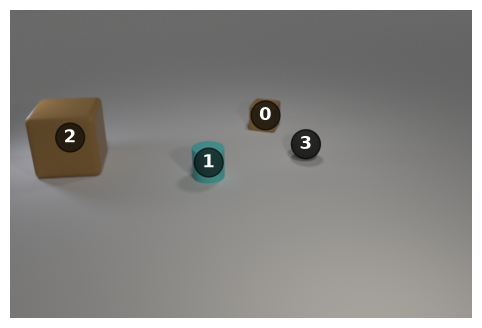

In [18]:
s_run = scenes[q_run["image_index"]]
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(plt.imread(IMAGES / s_run["image_filename"]))
for i, ob in enumerate(s_run["objects"]):
    x, y, _ = ob["pixel_coords"]
    ax.text(x, y, str(i), color="white", fontsize=13, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="circle", fc="black", alpha=0.6))
ax.axis("off")
plt.show()

**The symbols' values for this question.** First what the scene gives, for every position `o` (the scene has 4 objects, so positions 4 to 9 are empty): `Present(q, o)`, and the four attribute functions applied to `x[q, o]`. With perfect sight each function returns a one-hot vector, printed here as the value it picks.

In [19]:
x_run, present_run, rel_run = scene_cache[q_run["image_index"]]


def as_words(vec, a):
    # a one-hot vector as its value, all-ones as "any", all-zeros as "-"
    if bool((vec == 1).all()):
        return "any (all-ones)"
    if bool((vec == 0).all()):
        return "-"
    return VALUES[a][int(vec.argmax())]


print(f"{'o':>2s}  {'Present':>7s}  " + "  ".join(f"{a + '(x[q, o])':>18s}" for a in ATTRS))
for o in range(O):
    cells = [as_words(x_run[o, OFFSET[a][0]:OFFSET[a][1]], a) for a in ATTRS]
    print(f"{o:2d}  {int(present_run[o]):7d}  " + "  ".join(f"{c:>18s}" for c in cells))

 o  Present      color(x[q, o])       size(x[q, o])   material(x[q, o])      shape(x[q, o])
 0        1               brown               small              rubber                cube
 1        1                cyan               small              rubber            cylinder
 2        1               brown               large              rubber                cube
 3        1                gray               small              rubber              sphere
 4        0                   -                   -                   -                   -
 5        0                   -                   -                   -                   -
 6        0                   -                   -                   -                   -
 7        0                   -                   -                   -                   -
 8        0                   -                   -                   -                   -
 9        0                   -                   -                   -         

Then what the question gives: the values of each filter slot, as vectors, and the relation of relate 0.

In [20]:
_, fil_run, rels_run = canonical(q_run["program"])
for k, vals in enumerate(fil_run):
    for a in ATTRS:
        vec = torch.ones(len(VALUES[a]))
        if a in vals:
            vec = torch.nn.functional.one_hot(torch.tensor(VALUES[a].index(vals[a])), len(VALUES[a])).float()
        print(f"{PARAM[a]}{k}[q] = {str(vec.int().tolist()):26s} -> {as_words(vec, a)}")
    print()
print(f"R0 = '{rels_run[0]}': R0(q, o1, o2) = 1 for the pairs (o1, o2) with o2 in front of o1:",
      [(int(i), int(j)) for i, j in torch.nonzero(rel_run[rels_run[0]])])

c0[q] = [1, 1, 1, 1, 1, 1, 1, 1]   -> any (all-ones)
z0[q] = [0, 1]                     -> large
m0[q] = [1, 1]                     -> any (all-ones)
s0[q] = [1, 0, 0]                  -> cube

c1[q] = [1, 1, 1, 1, 1, 1, 1, 1]   -> any (all-ones)
z1[q] = [1, 1]                     -> any (all-ones)
m1[q] = [1, 0]                     -> rubber
s1[q] = [1, 1, 1]                  -> any (all-ones)

R0 = 'front': R0(q, o1, o2) = 1 for the pairs (o1, o2) with o2 in front of o1: [(0, 1), (0, 2), (0, 3), (2, 1), (3, 1), (3, 2)]


**The atoms of filter 0 on every position.** Filter 0 ("the large cube") is `Present` times the four atoms below, evaluated by sLTN with the object variable `o1` free. The colour and material atoms are 1 for every real object, because `c0[q]` and `m0[q]` are all-ones; the size and shape atoms select. The last column, the product of all five (the conjunction of filter 0), is 1 only for the object that is present, large and a cube. So filter 0 picks exactly one object: the large brown cube, the third object of the scene, labelled 2 in the picture because the scene file numbers objects from 0. This column is the first phase of the next table. (On an empty position every atom is 0, since its attributes are all zeros; `Present` = 0 makes that explicit.)

In [21]:
atoms0 = {a: f"{IS[a]}({a}(x[q, o1]), {PARAM[a]}0[q])" for a in ATTRS}
with torch.no_grad():
    av = {a: by_name(it(sig.parse(f)), ["q", "o1"])[0] for a, f in atoms0.items()}
print(f"{'o':>2s}  {'Present':>7s}  " + "  ".join(f"{f:>32s}" for f in atoms0.values()) + f"  {'filter 0 = product':>18s}")
for o in range(O):
    prod = present_run[o] * torch.stack([av[a][o] for a in ATTRS]).prod()
    print(f"{o:2d}  {int(present_run[o]):7d}  " + "  ".join(f"{av[a][o].item():32.3f}" for a in ATTRS) + f"  {prod.item():18.3f}")

 o  Present       IsC(color(x[q, o1]), c0[q])        IsZ(size(x[q, o1]), z0[q])    IsM(material(x[q, o1]), m0[q])       IsS(shape(x[q, o1]), s0[q])  filter 0 = product
 0        1                             1.000                             0.000                             1.000                             1.000               0.000
 1        1                             1.000                             0.000                             1.000                             0.000               0.000
 2        1                             1.000                             1.000                             1.000                             1.000               1.000
 3        1                             1.000                             0.000                             1.000                             0.000               0.000
 4        0                             0.000                             0.000                             0.000                             0.000             

**The phases, one after the other.** The program narrows down the objects step by step, and the full formula only shows the end of it. To see the steps, we cut the formula after each phase and leave the object variable free (no ∃ in front of it). sLTN then gives one value per object: 1 if the object is still a candidate after that phase, 0 if not.

| Column | Formula, cut after the phase | Free in | Reads |
|---|---|---|---|
| filter 0 | `Present(q, o1) & (four atoms of filter 0 on o1)` | `o1` | o1 is a large cube |
| relate 0 | `Present(q, o2) & exists o1: (o1 is a large cube & R0(q, o1, o2))` | `o2` | o2 is in front of the large cube |
| filter 1 | the previous one `& (four atoms of filter 1 on o2)` | `o2` | o2 is in front of the large cube and is matte |

Each column keeps only the objects that pass one more phase. The full formula then puts `exists o2` in front and adds "o2 has colour `kc`".

In [22]:
f0 = lambda v, k: " & ".join(f"{IS[a]}({a}(x[q, {v}]), {PARAM[a]}{k}[q])" for a in ATTRS)   # filter k on object v
phases = {   # name: (formula, its free object variable)
    "filter 0: large cube": (f"Present(q, o1) & {f0('o1', 0)}", "o1"),
    "relate 0: in front of it": (f"Present(q, o2) & exists o1: (Present(q, o1) & {f0('o1', 0)} & R0(q, o1, o2))", "o2"),
    "filter 1: and matte": (f"Present(q, o2) & exists o1: (Present(q, o1) & {f0('o1', 0)} & R0(q, o1, o2)) & {f0('o2', 1)}", "o2"),
}
with torch.no_grad():
    vals = {name: by_name(it(sig.parse(f)), ["q", v])[0] for name, (f, v) in phases.items()}
print(f"{'object':34s}" + "".join(f"{name:>27s}" for name in phases))
for i, ob in enumerate(s_run["objects"]):
    desc = f"{i}: {ob['size']} {ob['color']} {ob['material']} {ob['shape']}"
    print(f"{desc:34s}" + "".join(f"{vals[name][i].item():27.3f}" for name in phases))
print(f"\nR0 for this question = 'front': for each object, the objects in front of it: "
      f"{ dict(enumerate(s_run['relationships']['front'])) }")

object                                   filter 0: large cube   relate 0: in front of it        filter 1: and matte
0: small brown rubber cube                              0.000                      0.000                      0.000
1: small cyan rubber cylinder                           0.000                      1.000                      1.000
2: large brown rubber cube                              1.000                      0.000                      0.000
3: small gray rubber sphere                             0.000                      0.000                      0.000

R0 for this question = 'front': for each object, the objects in front of it: {0: [1, 2, 3], 1: [], 2: [1], 3: [1, 2]}


Filter 0 keeps object 2 (the large cube); relate 0 keeps the objects in front of it, only object 1; filter 1 keeps object 1, which is rubber: the matte thing in front of the large cube is the cyan cylinder. The whole question's formula, with `kc` free, then gives one truth value per colour: whether that object has that colour.

In [23]:
with torch.no_grad():
    v = by_name(it(sig.parse(c["formula"])), ["q", "kc"])[0]
for name, val in zip(VALUES["color"], v.tolist()):
    print(f"  {name:7s} {val:.6f}")
print("sLTN's reply:", VALUES["color"][int(v.argmax())], "| dataset's answer:", q_run["answer"])

  gray    0.000007
  red     0.000001
  blue    0.000001
  green   0.000001
  brown   0.000007
  purple  0.000001
  cyan    1.000000
  yellow  0.000001
sLTN's reply: cyan | dataset's answer: cyan


## 5. Every validation question

For each skeleton: compile its formula once from one of its questions, ground all its questions as one batch, and compare.
- **yes/no:** the question's formula's value, thresholded at 0.5, against the dataset's yes/no;
- **query:** the value with the highest truth value, against the dataset's answer. We also check that the formula is crisp: exactly one value above 0.5.

We also evaluate each family's rule, which is what training will maximise (Section 3.5).

In [24]:
t0 = time.perf_counter()
rows = []
for key, group in sorted(by_key.items(), key=lambda kv: -len(kv[1])):
    c = compile_family(group[0])
    assert all(compile_family(q)["formula"] == c["formula"] for q in group[:50])   # one formula per skeleton
    yes, ans = ground(it, group, c)
    with torch.no_grad():
        r = it(sig.parse(c["formula"]))
        sat = it(sig.parse(c["rule"])).value.item()
    if c["kind"] == "yesno":
        v = by_name(r, ["q"])
        ok = (v > 0.5) == yes.bool()
        one_true = float("nan")
    else:
        v = by_name(r, ["q", KVAR[c["kind"]]])
        ok = v.argmax(-1) == ans[c["kind"]].argmax(-1)
        one_true = ((v > 0.5).sum(-1) == 1).float().mean().item()
    rows.append(dict(key=key, kind=c["kind"], type=qtype(group[0]), n=len(group),
                     agree=ok.float().mean().item(), one_true=one_true, sat=sat,
                     families=sorted({q["question_family_index"] for q in group})))
print(f"{len(rows)} formulas, {sum(r['n'] for r in rows)} questions, {time.perf_counter() - t0:.0f}s")

56 formulas, 101028 questions, 15s


In [25]:
print(f"{'type':8s} {'questions':>9s} {'agreement':>10s}")
for t in ("exist", "compare", "query"):
    sel = [r for r in rows if r["type"] == t]
    n = sum(r["n"] for r in sel)
    print(f"{t:8s} {n:9d} {sum(r['agree'] * r['n'] for r in sel) / n:10.5f}")
n = sum(r["n"] for r in rows)
print(f"{'all':8s} {n:9d} {sum(r['agree'] * r['n'] for r in rows) / n:10.5f}")
print(f"\nformulas with any disagreement: {sum(r['agree'] < 1 for r in rows)}")
print(f"query questions with exactly one value true: {min(r['one_true'] for r in rows if r['kind'] != 'yesno'):.5f} (min over formulas)")
print(f"rule satisfaction: min {min(r['sat'] for r in rows):.4f}, max {max(r['sat'] for r in rows):.4f}")

type     questions  agreement
exist        20196    1.00000
compare      27098    1.00000
query        53734    1.00000
all         101028    1.00000

formulas with any disagreement: 0
query questions with exactly one value true: 1.00000 (min over formulas)
rule satisfaction: min 0.9986, max 0.9990


The formulas, largest first, with their families and the agreement:

In [26]:
for r in rows:
    print(f"{r['n']:5d}  {r['agree']:.4f}  sat {r['sat']:.4f}  families {r['families']}  {r['key']}")

 3422  1.0000  sat 0.9990  families [36, 44]  exist(F(same_size(unique(F(scene())))))
 3374  1.0000  sat 0.9990  families [39, 47]  exist(F(same_shape(unique(F(scene())))))
 3341  1.0000  sat 0.9990  families [37, 45]  exist(F(same_color(unique(F(scene())))))
 3325  1.0000  sat 0.9990  families [38, 46]  exist(F(same_material(unique(F(scene())))))
 1782  1.0000  sat 0.9990  families [19]  equal_material(query_material(unique(F(relate(unique(F(scene())))))),query_material(unique(F(scene()))))
 1768  1.0000  sat 0.9986  families [32]  query_size(unique(F(intersect(F(relate(unique(F(scene())))),F(relate(unique(F(scene()))))))))
 1750  1.0000  sat 0.9986  families [56]  query_material(unique(F(same_color(unique(F(scene()))))))
 1748  1.0000  sat 0.9990  families [26]  exist(F(relate(unique(F(relate(unique(F(relate(unique(F(scene())))))))))))
 1743  1.0000  sat 0.9990  families [24]  equal_shape(query_shape(unique(F(relate(unique(F(scene())))))),query_shape(unique(F(relate(unique(F(scene())

## 6. Findings

- **The translation is exact.** With perfect sight, the 56 formulas reproduce the dataset's answer on all 101,028 in-scope validation questions (exist, compare and query alike), and every "what ...?" formula makes exactly one value true. The script `e0_perfect_sight.py` runs the same check on the training split: 471,489 questions, all reproduced (run on 2026-11-09, CPU, 108 s). So any error made later, when the attributes come from networks, is an error of the networks, not of the formulas.
- **The rules are satisfied up to the aggregator's ceiling.** Rule satisfaction is 0.999 for yes/no families and 0.9986 for query families, not 1. This comes from the stable pMeanError used for ∀: it keeps its mean of squared errors at least ε = 10⁻⁶ away from 0, so a single ∀ reaches at most 1 − √ε = 0.999. A query rule nests two ∀ (over the values, then over the questions), so the inner 0.999 becomes about 1 − √(2ε) ≈ 0.9986 at the outer one. The ceiling is the same for every family, so it doesn't change which rules are satisfied.
- **Why ∃ = max matters.** It makes "the large cube" exact: 1 for the one object that matches and 0 for the others, whatever the number of objects. With the default pMean the answer of a perfect-sight formula would depend on how many objects the scene has.
- **The layout scales.** One structural axis for the questions and one for the objects lets a whole family, with every question about a different scene with different values, be evaluated in a single pass.

**Next step:** replace perfect sight with learning. Each object gets a feature vector instead of its one-hot attributes, the attribute functions become a small network, and the rules of Section 3.5 are the only training signal. The attributes from the scene file are then used only to score the network.

**A later extension: learning the relations too.** Here left, right, front and behind are given. They could instead be computed by a network from the two objects' positions, and learned from the answers like the attributes, with axioms such as "left is the converse of right" and "right is transitive". The CLEVR paper finds that neural models don't learn the true meaning of these relations, which makes this an interesting test.